### 1. Mount Google Drive
This cell mounts your Google Drive to access files stored there.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 2. Check Dataset Zip File Existence
Verifies if the specified dataset zip file exists in Google Drive.

In [ ]:
import os

print(os.path.exists("/content/drive/MyDrive/datasets/ip02-dataset.zip"))

True


### 3. Get Dataset Zip File Size
Calculates and prints the size of the dataset zip file in megabytes.

In [ ]:
import os

size = os.path.getsize("/content/drive/MyDrive/datasets/ip02-dataset.zip")
print("Size in MB:", size / (1024*1024))

Size in MB: 3012.179412841797


### 4. Extract Dataset Zip File
Extracts the contents of the zip file to a specified directory. This might take some time for large datasets.

In [ ]:
import zipfile
import os
import shutil

zip_path = "/content/drive/MyDrive/datasets/ip02-dataset.zip"
extract_path = "/content/ip102_full"

# remove old folder if exists
if os.path.exists(extract_path):
    shutil.rmtree(extract_path)

print("⏳ Extracting... please wait")

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    for i, file in enumerate(zip_ref.namelist()):
        zip_ref.extract(file, extract_path)
        if i % 1000 == 0:
            print(f"Extracted {i} files...")

print("✅ Extraction COMPLETED!")

⏳ Extracting... please wait
Extracted 0 files...
Extracted 1000 files...
Extracted 2000 files...
Extracted 3000 files...
Extracted 4000 files...
Extracted 5000 files...
Extracted 6000 files...
Extracted 7000 files...
Extracted 8000 files...
Extracted 9000 files...
Extracted 10000 files...
Extracted 11000 files...
Extracted 12000 files...
Extracted 13000 files...
Extracted 14000 files...
Extracted 15000 files...
Extracted 16000 files...
Extracted 17000 files...
Extracted 18000 files...
Extracted 19000 files...
Extracted 20000 files...
Extracted 21000 files...
Extracted 22000 files...
Extracted 23000 files...
Extracted 24000 files...
Extracted 25000 files...
Extracted 26000 files...
Extracted 27000 files...
Extracted 28000 files...
Extracted 29000 files...
Extracted 30000 files...
Extracted 31000 files...
Extracted 32000 files...
Extracted 33000 files...
Extracted 34000 files...
Extracted 35000 files...
Extracted 36000 files...
Extracted 37000 files...
Extracted 38000 files...
Extracted 

### 5. List Content Directory
Lists the contents of the `/content` directory to verify the extraction path.

In [ ]:
import os
print(os.listdir("/content"))

['.config', 'drive', 'ip102_full', 'sample_data']


### 6. List Extracted Dataset Directory
Lists the top-level contents of the extracted dataset directory (`/content/ip102_full`).

In [ ]:
print(os.listdir("/content/ip102_full"))

['classification', 'val.txt', 'test.txt', 'classes.txt', 'train.txt']


### 7. List Classification Directory
Lists the contents of the `classification` subdirectory within the extracted dataset.

In [ ]:
import os

print(os.listdir("/content/ip102_full/classification"))

['train', 'val', 'test']


### 8. Define Dataset Paths
Sets up variables for the training, validation, and test dataset paths.

In [ ]:
base_path = "/content/ip102_full/classification"

train_path = os.path.join(base_path, "train")
val_path   = os.path.join(base_path, "val")
test_path  = os.path.join(base_path, "test")

### 9. Print Image Counts per Split
Displays the number of subdirectories (representing classes) in the training, validation, and test sets.

In [ ]:
import os

print("Train:", len(os.listdir(train_path)))
print("Val:", len(os.listdir(val_path)))
print("Test:", len(os.listdir(test_path)))

Train: 102
Val: 102
Test: 102


### 10. Define Basic Image Transformations
Defines image preprocessing transformations for resizing, converting to tensor, and normalizing.

In [ ]:
import torch
from torchvision import transforms
from PIL import ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True

# Smart Augmentation for IP102
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(45), # High rotation is safe for insect field photos
    transforms.ColorJitter(brightness=0.1, contrast=0.1), # Minimal to preserve identity
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

### 11. Define Advanced Data Loading and Augmentation
This cell defines more advanced data augmentation techniques and attempts to load a balanced subset of 12 target classes. *Note: This cell appears to redefine aspects that are also handled by cell 10 and 12, potentially leading to conflicts or overwrites depending on execution order.*

In [ ]:
import torch
from torchvision import datasets
from torch.utils.data import DataLoader, Subset
import numpy as np

# Selected 12 distinct/high-count classes
target_classes = ['34', '23', '72', '8', '102', '15', '47', '11', '4', '42', '65', '91']

# Load full base datasets
full_train_base = datasets.ImageFolder(train_path, transform=train_transform)
target_idx = [full_train_base.class_to_idx[c] for c in target_classes]

# Create Balanced Training Indices (Exactly 1000 per class)
balanced_indices = []
all_train_labels = [label for _, label in full_train_base.imgs]
for t_idx in target_idx:
    class_indices = [i for i, label in enumerate(all_train_labels) if label == t_idx]
    # Oversample to reach 1000 images per class
    chosen = np.random.choice(class_indices, 1000, replace=True)
    balanced_indices.extend(chosen)

# Create Datasets and DataLoaders
train_dataset = Subset(full_train_base, balanced_indices)

full_val = datasets.ImageFolder(val_path, transform=val_test_transform)
val_dataset = Subset(full_val, [i for i, (_, l) in enumerate(full_val.imgs) if l in target_idx])

full_test = datasets.ImageFolder(test_path, transform=val_test_transform)
test_dataset = Subset(full_test, [i for i, (_, l) in enumerate(full_test.imgs) if l in target_idx])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"Dataset Balanced: 12 classes, 1000 images each.")

### 12. Load Datasets and Class Names
Loads the image datasets for training, validation, and testing using `ImageFolder` and retrieves class names.

In [ ]:
from torchvision.datasets import ImageFolder

train_dataset = ImageFolder(train_path, transform=transform)
val_dataset   = ImageFolder(val_path, transform=transform)
test_dataset  = ImageFolder(test_path, transform=transform)

class_names = train_dataset.classes

print("Train:", len(train_dataset))
print("Val:", len(val_dataset))
print("Test:", len(test_dataset))
print("Classes:", len(class_names))

Train: 45095
Val: 7508
Test: 22619
Classes: 102


### 13. Create DataLoaders
Initializes `DataLoader` objects for the training, validation, and test datasets to efficiently feed data to the model.

In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False)

### 14. Set Device for Training
Checks for GPU availability and sets the device (CUDA or CPU) for model training.

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


### 15. Load and Configure ResNet50 Model
Loads a pre-trained ResNet50 model, freezes most layers, unfreezes the last block, and replaces the final fully connected layer to match the number of output classes.

In [ ]:
import torch.nn as nn
from torchvision import models

# Load ResNet50 with ImageNet weights
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)

# Freeze basic features, fine-tune specific features
for param in model.parameters():
    param.requires_grad = False
for param in model.layer4.parameters():
    param.requires_grad = True

# Modify final layer for our 12 classes
model.fc = nn.Linear(model.fc.in_features, 12)
model = model.to(device)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 119MB/s]


### 16. Define Loss Function and Optimizer
Sets up the `CrossEntropyLoss` as the criterion and `Adam` optimizer for training the model.

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)

### 17. Print Number of Images per Class
Iterates through the training directory to display the count of images for each class, providing insight into class distribution.

In [ ]:
import os

train_path = "/content/ip102_full/classification/train"

print("📊 Number of Images per Class:\n")
print("-" * 40)

for cls in os.listdir(train_path):
    cls_path = os.path.join(train_path, cls)

    if os.path.isdir(cls_path):
        count = len(os.listdir(cls_path))
        print(f"Class {cls:<5} | Images: {count:>5}")

print("-" * 40)

📊 Number of Images per Class:

----------------------------------------
Class 44    | Images:   314
Class 34    | Images:   203
Class 5     | Images:   303
Class 47    | Images:   492
Class 32    | Images:   147
Class 90    | Images:   135
Class 95    | Images:   292
Class 24    | Images:  2456
Class 76    | Images:   433
Class 46    | Images:   393
Class 85    | Images:   100
Class 17    | Images:    88
Class 67    | Images:  3186
Class 57    | Images:   228
Class 70    | Images:  3048
Class 23    | Images:   642
Class 22    | Images:  1018
Class 75    | Images:   103
Class 3     | Images:   631
Class 83    | Images:   232
Class 31    | Images:   139
Class 37    | Images:   473
Class 65    | Images:    84
Class 11    | Images:   242
Class 100   | Images:   274
Class 56    | Images:   281
Class 62    | Images:   169
Class 9     | Images:   331
Class 50    | Images:   845
Class 13    | Images:   245
Class 55    | Images:   111
Class 92    | Images:   484
Class 33    | Images:   175
Clas

### 18. Print Total Number of Images
Calculates and displays the total number of images across the training, validation, and test datasets.

In [ ]:
total = len(train_dataset) + len(val_dataset) + len(test_dataset)
print("Total images:", total)

Total images: 75222


### 19. Model Training Loop
Executes the training process for a specified number of epochs, including forward pass, backpropagation, and loss calculation for both training and validation sets.

In [ ]:
epochs = 5

for epoch in range(epochs):
    model.train()
    train_loss = 0

    for images, labels in train_loader:
        # IMPORTANT: Map folder IDs to 0-11 range
        labels = torch.tensor([target_idx.index(l) for l in labels]).to(device)
        images = images.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()



    # Validation
    model.eval()
    val_loss = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_loss/len(train_loader):.4f} | Val Loss: {val_loss/len(val_loader):.4f}")

Epoch 1/5 | Train Loss: 1.5655 | Val Loss: 1.3756
Epoch 2/5 | Train Loss: 1.0372 | Val Loss: 1.3275
Epoch 3/5 | Train Loss: 0.7089 | Val Loss: 1.3117
Epoch 4/5 | Train Loss: 0.4699 | Val Loss: 1.4353
Epoch 5/5 | Train Loss: 0.3197 | Val Loss: 1.4653


### 20. Calculate Test Accuracy
Evaluates the trained model's performance on the test dataset and prints the overall accuracy.

In [ ]:
model.eval()

correct = 0
total = 0


with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        labels_mapped = torch.tensor([target_idx.index(l) for l in labels]).to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels_mapped).sum().item()

        total += labels.size(0)

accuracy = 100 * correct / total
print(f"✅ Test Accuracy: {accuracy:.2f}%")

✅ Test Accuracy: 66.33%


### 21. Generate Confusion Matrix Data
Collects predictions and true labels from the test set to compute the confusion matrix.

In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)

### 22. Plot Confusion Matrix
Visualizes the generated confusion matrix to show the model's performance in classifying each class.

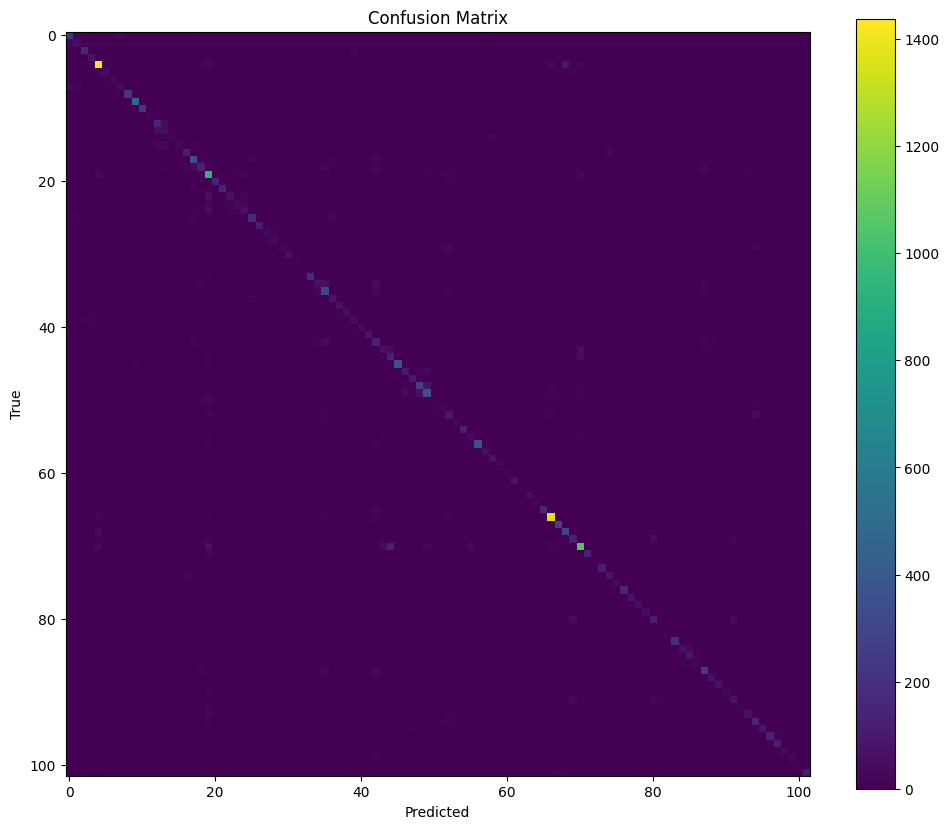

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,10))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.colorbar()

plt.xlabel("Predicted")
plt.ylabel("True")

plt.show()